# Links

GitHub repository:
https://github.com/nylandgit/IND320-Repo

Streamlit app:
https://nylandgit-ind320-repo.streamlit.app/

Code runthrough video:


# References

In the interest of avoiding claims of self-plagiarism (don't know if this is necessary for IND320?):

Bulks of the following code is copied and adapted from Thor Martin Nyland's Project Work Part 1. Parts of the code is copied directly without any modification. The AI Statement is copied directly, as there has been no change in AI usage since Part 1.

Parts of the code have been copied from khliland's IND320 GitHub Repository. These parts are highlighted where applicable.

# AI Statement and Descriptive Log

## AI Statement

This project has used the free VS Code Copilot generative AI to: Generate code, identify bugs, fix bugs, brainstorm technical solutions, and to teach the process of coding through in-depth explanations of each generated line of code. Some Google searches have also involved Google's built-in generative AI.

The project author has steered the AI's coding through accepting, rejecting, and modifying the AI's code based on the author's intuition. The author has requested code explanations, studied the AI's code, and made explanatory comments for each code block based on the author's understanding.

The code provided is therefore created partly by the author and partly by generative AI. The explanatory code comments are written exclusively by the author.

Anthropic's Claude was used to develop the Open-Meteo API data retreival code.

## Descriptive Log

### Section 1: Random Sampling of Shapefiles and Open-Meteo API Data Retrieval
* Copied and adapted the Atlas NVE shapefiles sampling example from class. Developed working demo for Precipitation Area sampling.
* Developed working demo for Electricity Area sampling.
* Developed working demo(s) for Open-Meteo API data retrieval based on Electricity Area samples. Built function download_region(region, start_date, end_date). The code is bloated and uncommented, will revise and explain code after plots are made and I understand the project requirements more deeply.
* Discovered that the Open-Meteo API demo only works for small time periods (max two months), as the number of retrieved rows R = h_per_day x days_2024 x n = 24 x 366 x 1000 = too much data for Open-Meteo's free plan.
* Reviewed Open-Meteo's limit documentation. Exactly one 2024 hourly download would fit within the 24h window, but the retrieval would take hours, as there is also an hourly weight limit. This also leaves no room for tests during development.
* Spent a very long time troubleshooting, trying other solutions. AI solutions mostly suck, makes me happy :) I would personally disregard the hourly data and instead care only about daily averages, as Magasinstatistikk already does, but the task text requires hourly data specifically. I assume this is related to later tasks and therefore not skipable.
* Temporarily skipped the data retrieval for all of 2024. Using only January-March 2024. Returning here after the rest of the work is done.
* Returned to the API problem, finally developed working code. Key changes involve using ERA5 cell deduplication (effectively reducing R by between 1/10 and 1/5), and not just caching retreived data but saving it to a .csv in case of kernel restarts, failed runs, etc.
* API data retrieval works!! :D
* I am still confused regarding the precipitation area shapefiles. I have not quite understood why these are necessary when they 1) do not overlap correctly with the electricity areas, and 2) electricity areas shapefiles are already enough (unless I've misunderstood something) to gather all relevant data. For the time being, the electricity areas are used in later code, and precipitation areas are not.

<p></p>
<p></p>

### Plots
* Made plot of average precipitation as a function of time.
* Performed high-pass DCT filtering of TEMPERATURE to create SATV. The task text describes filtering precipitation to create SATV, I assume this is a mistake, and that the instruction should not be "create seasonally adjusted temperature variations via high pass dct filtering of precipitation data" but rather "create seasonally adjusted temperature variations via high pass dct filtering of temperature data".
* Created SATV plot for temperature.
* Gone further and assumed precipitation and temperature "headline" bullet points have been switched in the task text. Switched average precipitation plot with average temperature plot.
* Created SPC plot for temperature.
* Created temperature function, combining code from above cells.
* Plotted precipitation as a function of time.
* Performed LOF on precipitation data, plots look odd but this is hard to judge as the full 2024 data is still not retrieved.
* Created precipitation function, combining code from above cells.
* Performed STL using LOESS on data from Magasinstatistikk API, reused code from part 2 to request relevant data.
* Created STL plots.
* Created Spectrogram.

<p></p>
<p></p>

### Streamlit
* Renamed pages as one step towards improving design and user experience. Will do a dashboard design overhaul during part 4 when I know all required functions.
* Pie Line page is still slow, will improve this during part 4. The figures here aren't as interconnected as I want them to be, will patch later.

# Non-Streamlit Code

## 1. Atlas NVE, Open-Meteo API

### 1.1 Precipitation Area Sampling

In [ ]:
# This code has been copied and adapted from Kristian Hovde Lilands IND320
# lecture held at NMBU on 26.10.2026.
import geopandas as gpd

# Reading relevant shapefile.
gdf_precip = gpd.read_file("../shapefiles/precipitation areas/NVE_Region.shp")

# Generating random points for sampling as instructed.
n = 1000
points_precip = gdf_precip['geometry'].sample_points(size=n, random_state=42)

# Transforming WGS84 (EPSG:4326) for latitude and longitude.
points_wgs84_precip = points_precip.to_crs(epsg=4326)

# Extracting coordinates and printing.
for idx_precip, multipoint_precip in points_wgs84_precip.items():
    region_name_precip = gdf_precip.loc[idx_precip, 'REGION']

    for point_precip in multipoint_precip.geoms:
        lat_precip = point_precip.y
        lon_precip = point_precip.x

print(lat_precip)


58.323602375408825


### 1.2 Electricity Areas Sampling

In [ ]:
# This code has been copied and adapted from Kristian Hovde Lilands IND320
# lecture held at NMBU on 26.10.2026.

import geopandas as gpd
import pandas as pd

# Reading relevant shapefile.
gdf_el = gpd.read_file("../shapefiles/electricity areas/Budområder.shp")

# Generating random points for sampling as instructed.
n = 1000
points_el = gdf_el['geometry'].sample_points(size=n, random_state=42)

# Transforming WGS84 (EPSG:4326) for latitude and longitude.
points_wgs84_el = points_el.to_crs(epsg=4326)

# Extracting and saving coordinates.
locations_by_region_el = {}
for idx_el, multipoint_el in points_wgs84_el.items():
    region_name_el = gdf_el.loc[idx_el, 'budomr']
    print(f"Region: {region_name_el}")

    for point_el in multipoint_el.geoms:
        lat_el = point_el.y
        lon_el = point_el.x
        locations_by_region_el.setdefault(region_name_el, []).append((lat_el, lon_el))

df_el = pd.DataFrame(locations_by_region_el)


Region: NO 1
Region: NO 2
Region: NO 3
Region: NO 4
Region: NO 5


In [6]:


print(lat_el)
print(df_el["NO 3"].tail())


60.96442453514546
995     (63.20825078853552, 10.237899298816169)
996    (62.820302488566085, 6.4792260605510945)
997      (62.46477340796964, 6.449608481553927)
998     (62.136191161668656, 8.713172381011924)
999      (61.66060870279023, 8.387054150283797)
Name: NO 3, dtype: object


### 1.3 API Data Retrieval Function download_region()

In [8]:
# The following code has been adapted from Open Meteo's Python coding
# example at https://open-meteo.com/en/docs/historical-forecast-api. It
# saves retrieved data to a locally stored .csv to avoid reruns during
# development.
import os
import time
import openmeteo_requests
import pandas as pd
import requests_cache
from retry_requests import retry

# Setting up Open-Meteo API client with cache and retry on error.
cache_session = requests_cache.CachedSession('.cache', expire_after = -1)
retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
openmeteo = openmeteo_requests.Client(session = retry_session)

# Defining function with input parameters as instructed.
def download_region(region, start_date, end_date):
    url = "https://archive-api.open-meteo.com/v1/archive"
    region_data = []

    # Loading saved csv if it exists, so the API only needs to be called once.
    # The f"{...} line looks for files named using the naming logic seen in
    # the last code block of this function.
    csv_file = f"{region.replace(' ', '_')}_{start_date}_{end_date}.csv"
    if os.path.exists(csv_file):
        print(f"Loading {csv_file} from disk, no API calls needed.", flush=True)
        saved = pd.read_csv(csv_file)

        # Converting to date column data to datetime objects (if they exist).
        saved["date"] = pd.to_datetime(saved["date"], utc=True).dt.tz_convert("Europe/Berlin")
        return saved



    locations = locations_by_region_el[region]

    # Getting the elevation of every sampled point from Open-Meteo's Elevation
    # API (max 100 coordinates per request), see code block below. Iterating
    # over sampled points in batches of 100.
    points = pd.DataFrame(locations, columns=["lat", "lon"])
    elevations = []
    for batch_start in range(0, len(points), 100):
        batch = points.iloc[batch_start:batch_start + 100]
        
        # Printing progress messages as program may for several minutes.
        print(f"Getting elevations for points {batch_start + 1}-"
              f"{batch_start + len(batch)}/{len(points)}...", flush=True)
        
        # Retrieving elevation data for each sampled point in iteration.
        elev_response = retry_session.get(
            "https://api.open-meteo.com/v1/elevation",
            params={"latitude": ",".join(map(str, batch["lat"])),
                    "longitude": ",".join(map(str, batch["lon"]))},
        )
        elev_response.raise_for_status()
        elevations += elev_response.json()["elevation"]
    points["elevation"] = elevations



    # Merging sampled points into ERA5 grid cells (0.25 degrees). Each cell is
    # requested once, at the mean position and mean elevation of the sampled
    # points inside it. "weight" is the number of sampled points in the cell.
    # This saves API weighted cost, making the retrieval possible with the
    # API's free plan data limits.
    points["cell_lat"] = (points["lat"] / 0.25).round() * 0.25
    points["cell_lon"] = (points["lon"] / 0.25).round() * 0.25
    
    # Defining cells to be called at mean of lon/lat and elevation.
    cells = points.groupby(["cell_lat", "cell_lon"]).agg(
        lat=("lat", "mean"), lon=("lon", "mean"),
        elevation=("elevation", "mean"), weight=("lat", "size"),
    ).reset_index()
    print(f"Merged {len(points)} points into {len(cells)} ERA5 cells.", flush=True)



    # Setting up chunk-based API data requesting (lots of data).
    chunk_size = 10
    total_chunks = (len(cells) + chunk_size - 1) // chunk_size

    # Iterating over each chunk.
    for chunk_number, chunk_start in enumerate(
        range(0, len(cells), chunk_size), start=1):
        
        chunk = cells.iloc[chunk_start:chunk_start + chunk_size]

        # Defining parameters as instructed by Open-Meteo API.
        params = {
            "latitude": chunk["lat"].tolist(),
            "longitude": chunk["lon"].tolist(),
            "elevation": chunk["elevation"].tolist(),
            "start_date": start_date,
            "end_date": end_date,
            "hourly": ["temperature_2m", "precipitation"],
            "models": "era5",
            "timezone": "Europe/Berlin",}

        # Printing progress messages (long code execution times).
        print(
            f"Attempting chunk {chunk_number}/{total_chunks} "
            f"({len(chunk)} cells) for region {region}...",
            flush=True,)



        responses = openmeteo.weather_api(url, params=params)

        # Iterating over each ERA5 cell.
        for (_, cell), response in zip(chunk.iterrows(), responses):
            hourly = response.Hourly()

            # Creating dictionary to be populated with data from API.
            hourly_data = {

                # Defining "date" key:value pair(s), this is converted to a df
                # column later. Essentially, this block defines the "date"
                # column in our soon-to-exist df. Methodology is from API.
                "date": pd.date_range(
                    start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                    end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                    freq=pd.Timedelta(seconds=hourly.Interval()),
                    inclusive="left",
                ).tz_convert(response.Timezone().decode()),

                # Defining temp. and precip. key:value pairs for soon-to-exist df.
                "temperature_2m": hourly.Variables(0).ValuesAsNumpy(),
                "precipitation": hourly.Variables(1).ValuesAsNumpy(),}

            # Converting data dictionary to pandas df.
            point_data = pd.DataFrame(data=hourly_data)
            point_data["latitude"] = cell["lat"]
            point_data["longitude"] = cell["lon"]
            point_data["elevation"] = cell["elevation"]
            point_data["weight"] = int(cell["weight"])
            region_data.append(point_data)

        print(f"Completed chunk {chunk_number}/{total_chunks}.", flush=True)

        # Pausing between chunks to stay under the API's per-minute limit.
        time.sleep(10)

    # Saving everything to csv so the API call only needs to be done once.
    region_data = pd.concat(region_data, ignore_index=True)
    region_data.to_csv(csv_file, index=False)
    print(f"Saved {len(region_data)} rows to {csv_file}.", flush=True)
    return region_data

no3_2024 = download_region("NO 3", "2024-01-01", "2024-12-31")


Getting elevations for points 1-100/1000...
Getting elevations for points 101-200/1000...
Getting elevations for points 201-300/1000...
Getting elevations for points 301-400/1000...
Getting elevations for points 401-500/1000...
Getting elevations for points 501-600/1000...
Getting elevations for points 601-700/1000...
Getting elevations for points 701-800/1000...
Getting elevations for points 801-900/1000...
Getting elevations for points 901-1000/1000...
Merged 1000 points into 301 ERA5 cells.
Attempting chunk 1/31 (10 cells) for region NO 3...
Completed chunk 1/31.
Attempting chunk 2/31 (10 cells) for region NO 3...
Completed chunk 2/31.
Attempting chunk 3/31 (10 cells) for region NO 3...
Completed chunk 3/31.
Attempting chunk 4/31 (10 cells) for region NO 3...
Completed chunk 4/31.
Attempting chunk 5/31 (10 cells) for region NO 3...
Completed chunk 5/31.
Attempting chunk 6/31 (10 cells) for region NO 3...
Completed chunk 6/31.
Attempting chunk 7/31 (10 cells) for region NO 3...
Compl

In [9]:
print(no3_2024)

print(len(locations_by_region_el["NO 3"]))


                             date  temperature_2m  precipitation   latitude  \
0       2024-01-01 00:00:00+01:00           5.600            0.1  61.042908   
1       2024-01-01 01:00:00+01:00           5.500            0.0  61.042908   
2       2024-01-01 02:00:00+01:00           5.350            0.0  61.042908   
3       2024-01-01 03:00:00+01:00           5.250            0.0  61.042908   
4       2024-01-01 04:00:00+01:00           5.100            0.0  61.042908   
...                           ...             ...            ...        ...   
2643979 2024-12-31 19:00:00+01:00          -1.111            0.2  65.189993   
2643980 2024-12-31 20:00:00+01:00          -0.911            0.4  65.189993   
2643981 2024-12-31 21:00:00+01:00          -1.511            0.4  65.189993   
2643982 2024-12-31 22:00:00+01:00          -1.361            0.1  65.189993   
2643983 2024-12-31 23:00:00+01:00          -3.261            0.3  65.189993   

         longitude  elevation  weight  
0         4

## 2. Temperature Plots and Function

### 2.1 Plotting Average Temperature as Function of Time

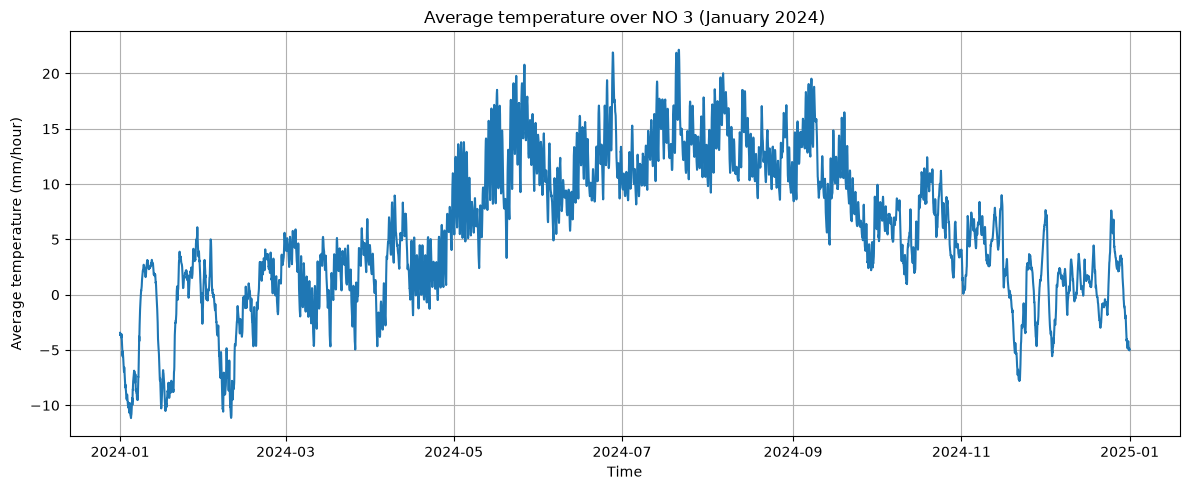

date
2024-01-01 00:00:00+01:00   -3.448711
2024-01-01 01:00:00+01:00   -3.520971
2024-01-01 02:00:00+01:00   -3.653363
2024-01-01 03:00:00+01:00   -3.622964
2024-01-01 04:00:00+01:00   -3.654193
Name: temperature_2m, dtype: float32


In [10]:
import matplotlib.pyplot as plt

# Taking the average hourly temperature across all 1000 sampled points.
temp_avg = no3_2024.groupby("date")["temperature_2m"].mean().sort_index()

# Plotting.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(temp_avg.index, temp_avg.values)

ax.set(
    title="Average temperature over NO 3 (January 2024)",
    xlabel="Time",
    ylabel="Average temperature (mm/hour)",
)
ax.grid(True)
fig.tight_layout()
plt.show()

print(temp_avg.head())


### 2.2 SATV from High-Pass Discrete Cosine Transform

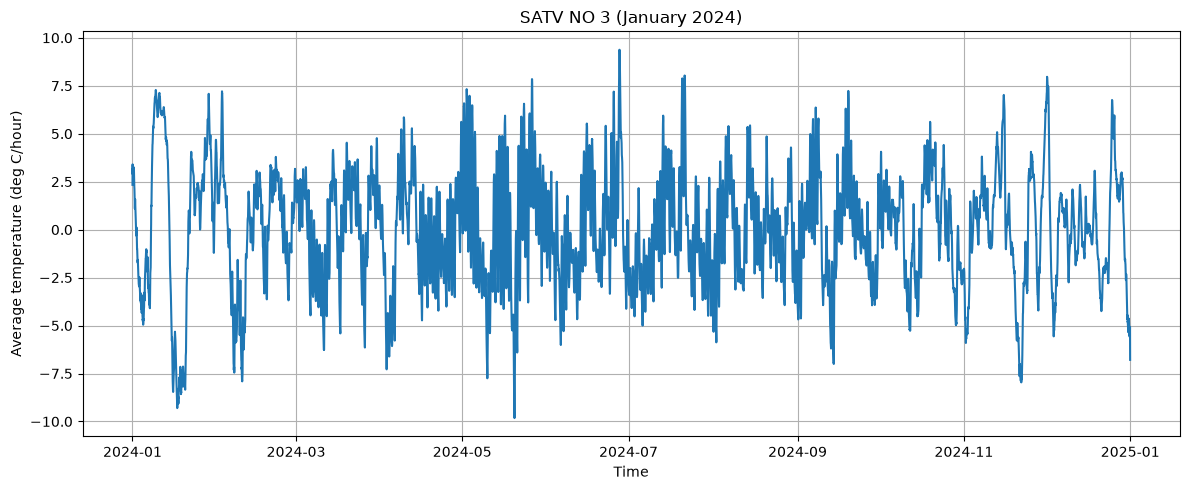

In [11]:
import numpy as np
from scipy.fft import dct, idct

# Defining n = number of observations for avg temperature.
temp_avg_np = temp_avg.to_numpy(dtype=float)
n = len(temp_avg_np)

# Defining cutoff (24 hours/day * 30 days) period and frequency.
cutoff_period_hours = 30 * 24
f = np.arange(n) / (2 * n)  # cycles per hourly sample

# Performing DCT. dct() transforms temperature values from the time domain to
# DCT coefficients, which are then set to zero if their frequencies are below
# the cutoff frequency. This effectively removes fluctuations with periods
# longer than the cutoff.
coefficients = dct(temp_avg_np, type=1, norm="ortho")
coefficients[f < 1 / cutoff_period_hours] = 0

# Creating a pandas Series of the remaining coefficients, after converting
# these back into the time domain using idct(). Voila! High-pass filtering :D
high_pass_temp = pd.Series(
    idct(coefficients, type=2, norm="ortho"),
    index=temp_avg.index,
    name="high_pass_precipitation",
)

# Plotting.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(high_pass_temp.index, high_pass_temp.values)

ax.set(
    title="SATV NO 3 (January 2024)",
    xlabel="Time",
    ylabel="Average temperature (deg C/hour)",
)
ax.grid(True)
fig.tight_layout()
plt.show()


### 2.3 Statistical Process Control (Temperature)

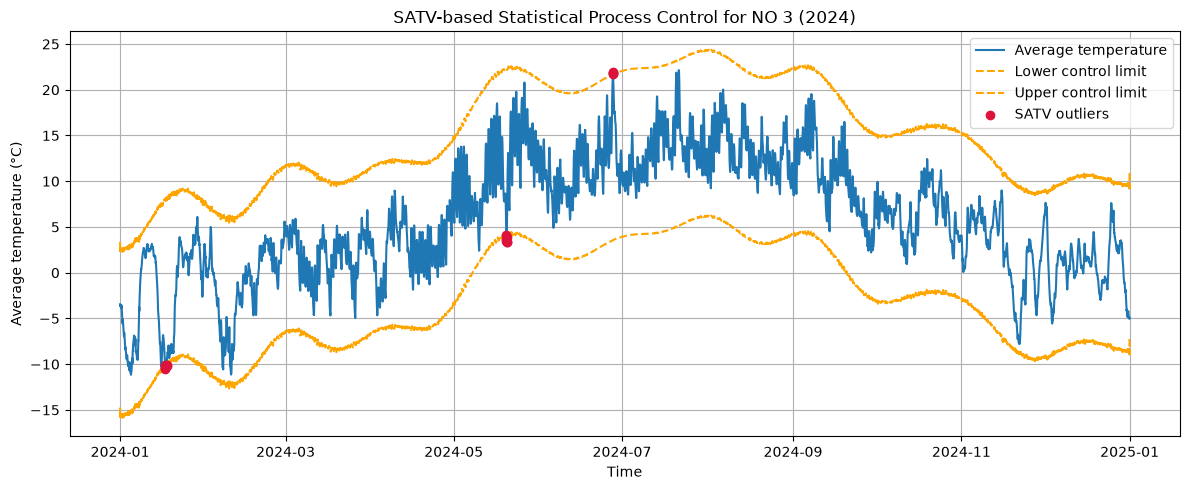

In [12]:
# Using SATV from 2.2 to estimate robust limits for the time period.
# Using .reindex() and .median() to find the middle point of temp_avg sorted
# by temp, ascending order.
satv = high_pass_temp.reindex(temp_avg.index)
satv_median = satv.median()

# Assuming normal distribution and defining outlier limit to be +-3 STD as
# explained by the D2D book.
robust_sigma = 1.4826 * (satv - satv_median).abs().median()
satv_lcl = satv_median - 3 * robust_sigma
satv_ucl = satv_median + 3 * robust_sigma

# Identifying outliers from SATV.
outliers = (satv < satv_lcl) | (satv > satv_ucl)

# Translating outliers back into temperature.
baseline = temp_avg - satv
lcl = baseline + satv_lcl
ucl = baseline + satv_ucl

# Plotting avg temperature and its SATV-based control limits.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(temp_avg.index, temp_avg.values, label="Average temperature")
ax.plot(temp_avg.index, lcl, color="orange", linestyle="--", label="Lower control limit")
ax.plot(temp_avg.index, ucl, color="orange", linestyle="--", label="Upper control limit")
ax.scatter(satv.index[outliers], temp_avg.loc[outliers], color="crimson",
           label="SATV outliers", zorder=3)

ax.set(
    title="SATV-based Statistical Process Control for NO 3 (2024)",
    xlabel="Time",
    ylabel="Average temperature (°C)",
)
ax.grid(True)
ax.legend()
fig.tight_layout()
plt.show()


### 2.4 Temperature Function

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.fft import dct, idct

def temp_function(cutoff_f = np.arange(n) / (2 * n), stdev_n=3):

    # Taking the average hourly temperature across all 1000 sampled points.
    temp_avg = no3_2024.groupby("date")["temperature_2m"].mean().sort_index()
    
    # Defining n = number of observations for avg temperature.
    temp_avg_np = temp_avg.to_numpy(dtype=float)
    n = len(temp_avg_np)

    # Defining cutoff period (24 hours/day * 30 days) and frequency.
    cutoff_period_hours = 24 * 30

    # Performing DCT. dct() transforms temperature values from the time domain
    # to DCT coefficients, which are then set to zero if their frequencies are
    # below the cutoff frequency. This effectively removes fluctuations with
    # periods longer than the cutoff.
    coefficients = dct(temp_avg_np, type=1, norm="ortho")
    coefficients[cutoff_f < 1 / cutoff_period_hours] = 0

    # Creating a pandas Series of the remaining coefficients, after converting
    # these back into the time domain using idct(). Voila! High-pass filtering :D
    high_pass_temp = pd.Series(
        idct(coefficients, type=2, norm="ortho"),
        index=temp_avg.index,
        name="SATV",
    )

    # Assuming normal distribution and defining outlier limit to be +-3 STD as
    # explained by the D2D book.
    satv_median = high_pass_temp.median()
    robust_sigma = 1.4826 * (high_pass_temp - satv_median).abs().median()
    satv_lcl = satv_median - stdev_n * robust_sigma
    satv_ucl = satv_median + stdev_n * robust_sigma

    # Identifying outliers from SATV.
    outliers = (high_pass_temp < satv_lcl) | (high_pass_temp > satv_ucl)

    # Translating outliers back into temperature.
    baseline = temp_avg - high_pass_temp
    lcl = baseline + satv_lcl
    ucl = baseline + satv_ucl

    # Plotting avg temperature and its SATV-based control limits.
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(temp_avg.index, temp_avg.values, label="Average temperature")
    ax.plot(temp_avg.index, lcl, color="orange", linestyle="--", label="Lower control limit")
    ax.plot(temp_avg.index, ucl, color="orange", linestyle="--", label="Upper control limit")
    ax.scatter(high_pass_temp.index[outliers], temp_avg.loc[outliers], color="crimson", label="SATV outliers", zorder=3)
    ax.set(
        title="SATV-based Statistical Process Control for NO 3 (2024)",
        xlabel="Time",
        ylabel="Average temperature (°C)",
    )
    ax.grid(True)
    ax.legend()
    fig.tight_layout()

    outlier_details = pd.DataFrame({
        "average_temperature": temp_avg[outliers],
        "SATV": high_pass_temp[outliers],
    })
    outlier_summary = outlier_details["average_temperature"].agg(["count", "mean", "min", "max"])

    return fig, outlier_details, outlier_summary


### 2.5 Function Test

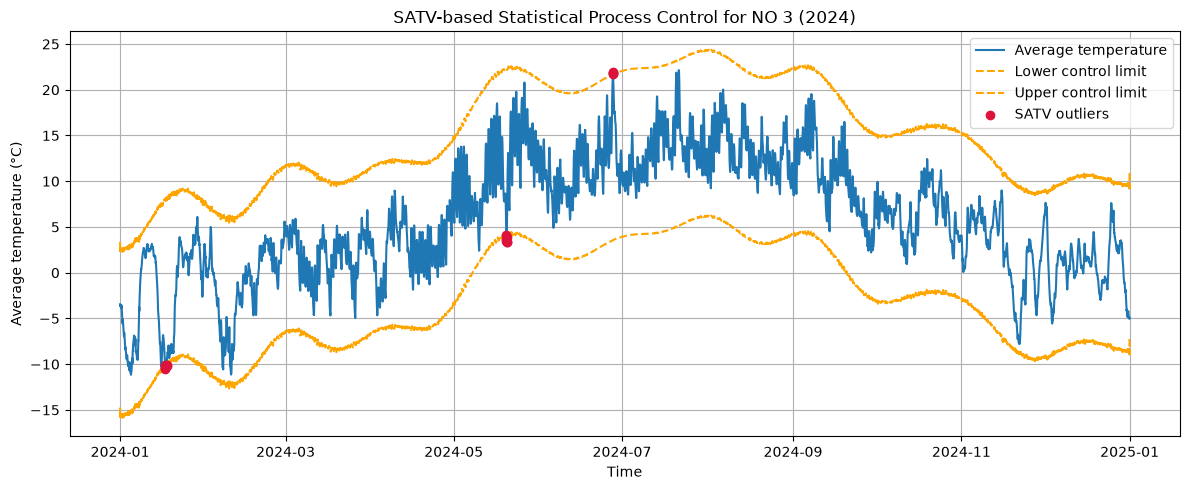

,average_temperature,SATV
date,,
2024-01-17 08:00:00+01:00,-10.132598,-9.008116
2024-01-17 09:00:00+01:00,-10.326451,-9.156567
2024-01-17 10:00:00+01:00,-10.455688,-9.302891
2024-01-17 11:00:00+01:00,-10.512831,-9.234988
2024-01-17 20:00:00+01:00,-10.161336,-9.071982
2024-01-17 21:00:00+01:00,-10.083097,-8.996512
2024-05-20 01:00:00+02:00,4.144146,-9.034873
2024-05-20 02:00:00+02:00,3.709262,-9.465227
2024-05-20 03:00:00+02:00,3.413249,-9.740356


count    16.000000
mean      2.965201
min     -10.512831
max      21.895308
Name: average_temperature, dtype: float64

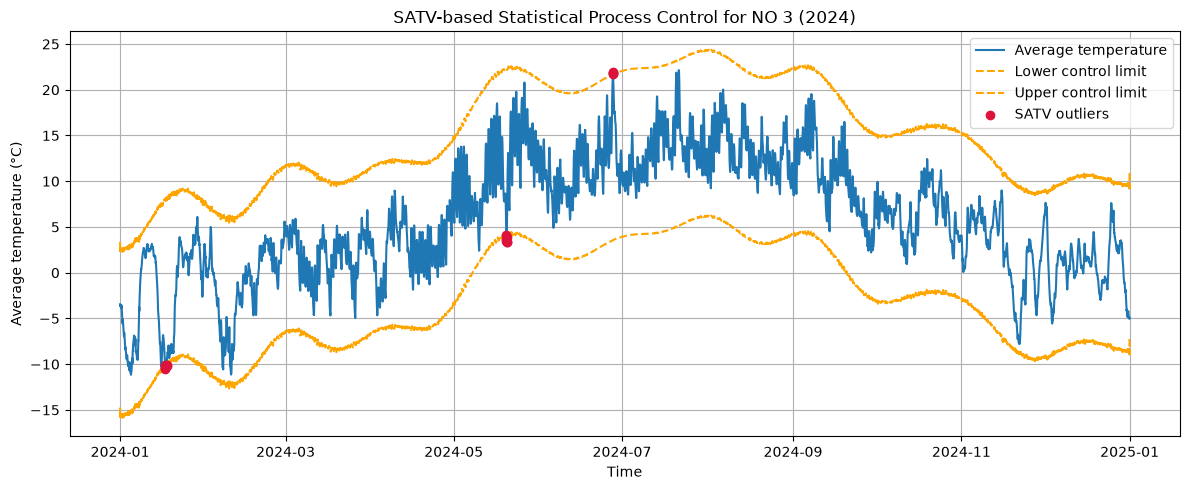

In [14]:
fig, outlier_details, outlier_summary = temp_function()
display(fig)
display(outlier_details)
display(outlier_summary)


## 3. Precipitation Plots and Function

### 3.1 Plotting Average Precipitation as Function of Time

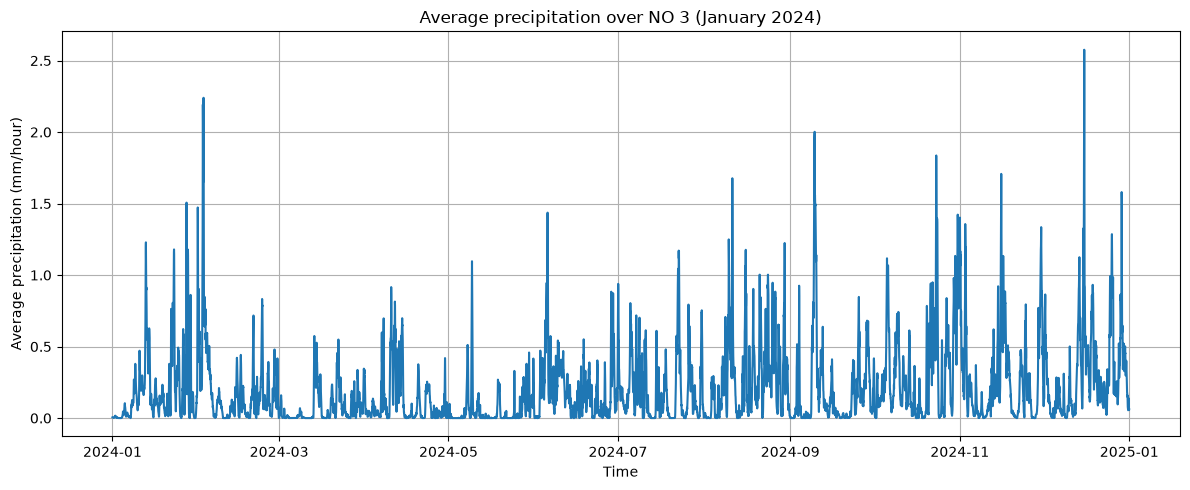

date
2024-01-01 00:00:00+01:00    0.004983
2024-01-01 01:00:00+01:00    0.004651
2024-01-01 02:00:00+01:00    0.003654
2024-01-01 03:00:00+01:00    0.003654
2024-01-01 04:00:00+01:00    0.003654
Name: precipitation, dtype: float32


In [15]:
import matplotlib.pyplot as plt

# Taking the average hourly precipitation across all 1000 sampled points.
precip_avg = no3_2024.groupby("date")["precipitation"].mean().sort_index()

# Plotting.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(precip_avg.index, precip_avg.values)

ax.set(
    title="Average precipitation over NO 3 (January 2024)",
    xlabel="Time",
    ylabel="Average precipitation (mm/hour)",
)
ax.grid(True)
fig.tight_layout()
plt.show()

print(precip_avg.head())


### 3.2 Anomaly Indication Using Local Outlier Factor

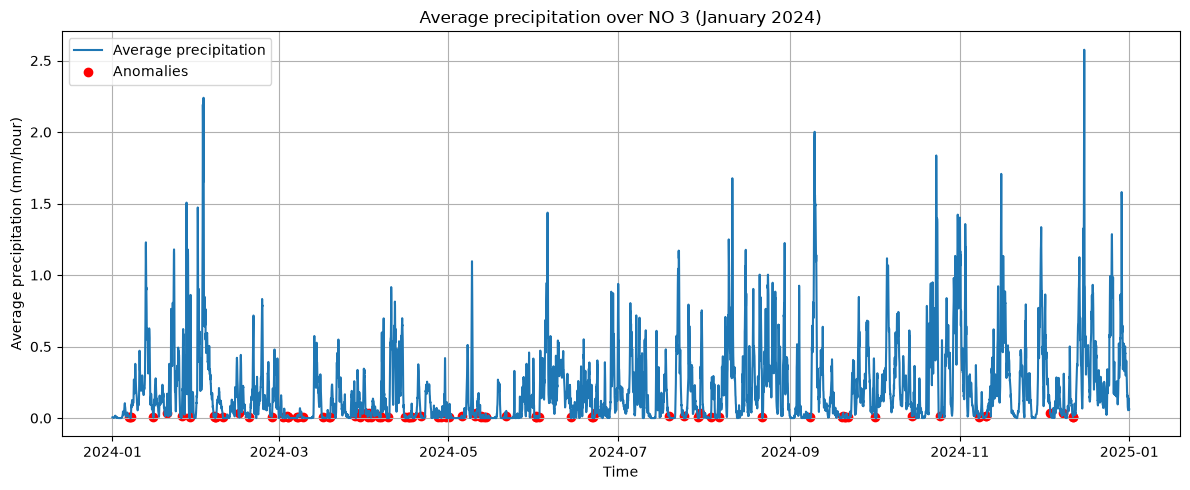

In [16]:
from sklearn.neighbors import LocalOutlierFactor

# Defining outlier proportion as instructed by task text.
outlier_proportion = 0.01

# Transforming precip_avg pd Series to numpy array for use in
# LocalOutlierFactor().
lof_data = precip_avg.to_numpy().reshape(-1, 1)

# Using LocalOutlierFactor() as instructed by D2D book.
lof = LocalOutlierFactor(contamination=outlier_proportion)
labels = lof.fit_predict(lof_data)
anomalies = labels == -1

# Plotting w/ anomalies.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(precip_avg.index, precip_avg.values, label="Average precipitation")
ax.scatter(
    precip_avg.index[anomalies],
    precip_avg[anomalies],
    color="red",
    label="Anomalies",
)
ax.set(
    title="Average precipitation over NO 3 (January 2024)",
    xlabel="Time",
    ylabel="Average precipitation (mm/hour)",
)
ax.grid(True)
ax.legend()
fig.tight_layout()
plt.show()


### 3.3 Precipitation Function

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neighbors import LocalOutlierFactor

def precipitation_function(outlier_proportion=0.01):

    # Transforming precip_avg pd Series to numpy array for use in
    # LocalOutlierFactor().
    lof_data = precip_avg.to_numpy().reshape(-1, 1)

    # Using LocalOutlierFactor() as instructed by D2D book.
    lof = LocalOutlierFactor(contamination=outlier_proportion)
    labels = lof.fit_predict(lof_data)
    anomalies = labels == -1

    # Plotting w/ anomalies, outlier details.
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(precip_avg.index, precip_avg.values, label="Average precipitation")
    ax.scatter(
        precip_avg.index[anomalies],
        precip_avg[anomalies],
        color="red",
        label="Anomalies",
    )
    ax.set(
        title="Average precipitation over NO 3 (January 2024)",
        xlabel="Time",
        ylabel="Average precipitation (mm/hour)",
    )
    ax.grid(True)
    ax.legend()
    fig.tight_layout()
    
    outlier_details = pd.DataFrame({
        "average_precipitation": precip_avg[anomalies]})
    
    outlier_summary = outlier_details.agg(["count", "mean", "min", "max"])

    return fig, outlier_details, outlier_summary


### 3.4 Function Test

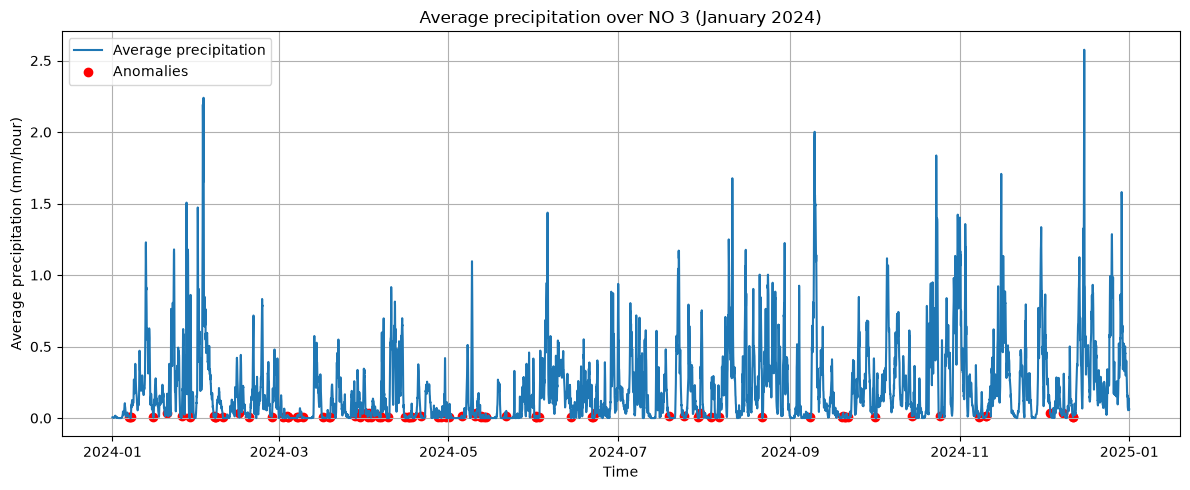

,average_precipitation
date,
2024-01-07 01:00:00+01:00,0.008638
2024-01-07 06:00:00+01:00,0.009302
2024-01-07 15:00:00+01:00,0.006312
2024-01-15 16:00:00+01:00,0.009302
2024-01-20 13:00:00+01:00,0.033887
...,...
2024-11-10 10:00:00+01:00,0.014286
2024-12-03 14:00:00+01:00,0.033887
2024-12-08 00:00:00+01:00,0.033887


,average_precipitation
count,88.000000
mean,0.012455
min,0.006312
max,0.033887


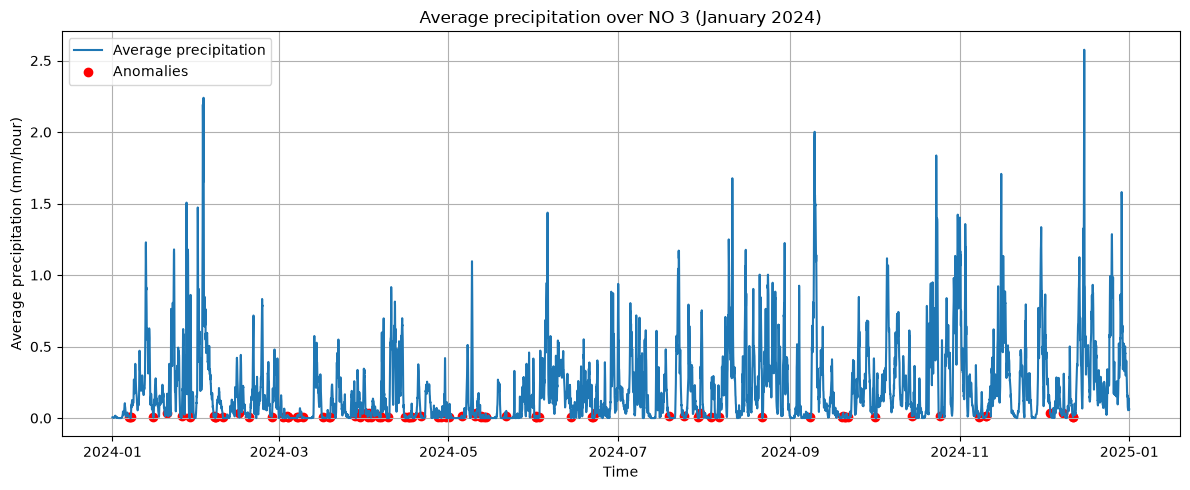

In [18]:
fig_precip, outlier_details_precip, outlier_summary_precip = precipitation_function()
display(fig_precip)
display(outlier_details_precip)
display(outlier_summary_precip)


## 4. STL using LOESS on Magasinstatistikk Data, Spectrogram

### 4.1 Retrieving Magasinstatistikk API Data

In [21]:
# This code is copied from project_work_part2.ipynb

# Retrieving data from Magasinstatistikk API.
import requests

url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

# Retrieving data from API with .get().
response = requests.get(url, timeout=120)
response.raise_for_status()

# Transforming API to DataFrame.
import pandas as pd
import matplotlib.pyplot as plt

# Transforming API data to pandas df.
df_mag = pd.DataFrame(response.json())

# Translating Norwegian column names into understandable English.
df_mag = df_mag.rename(columns={
    "dato_Id": "Date",
    "omrType": "Area Type",
    "omrnr": "Area Number",
    "iso_aar": "ISO Year",
    "iso_uke": "ISO Week",
    "fyllingsgrad": "Filling Ratio",
    "kapasitet_TWh": "Capacity TWh",
    "fylling_TWh": "Filling TWh",
    "neste_Publiseringsdato": "Next Publishing Date",
    "fyllingsgrad_forrige_uke": "FR Last Week",
    "endring_fyllingsgrad": "Change FR",
})

# Transforming API dates into datetime objects; sorting columns by date.
df_mag["Date"] = pd.to_datetime(df_mag["Date"])
df_mag = df_mag.sort_values("Date", ascending=True)

print(df_mag.head())


            Date Area Type  Area Number  ISO Year  ISO Week  Filling Ratio  \
2980  1995-01-08        EL            5      1995         1       0.616448   
14350 1995-01-08      VASS            1      1995         1       0.635440   
7118  1995-01-08        EL            2      1995         1       0.630947   
4415  1995-01-08        EL            3      1995         1       0.602376   
7718  1995-01-08        EL            1      1995         1       0.617574   

       Capacity TWh  Filling TWh Next Publishing Date  FR Last Week  Change FR  
2980      17.390587    10.720388  0001-01-01T00:00:00      0.614288   0.002160  
14350     36.044464    22.904102  0001-01-01T00:00:00      0.756482  -0.121041  
7118      34.043590    21.479713  0001-01-01T00:00:00      0.777604  -0.146657  
4415       8.920932     5.373754  0001-01-01T00:00:00      0.596027   0.006349  
7718       6.003264     3.707457  0001-01-01T00:00:00      0.583705   0.033869  


### 4.2 STL using LOESS

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

# Defining function w/ requested parameters and relevant defaults.
def plot_stl_decomposition(
    df_mag,
    area_type="EL",
    area_number=3,
    seasonal=13,
    trend=53,
    robust=False,):

    # Selecting data by area type and number function parameters.
    data = df_mag.loc[
        (df_mag["Area Type"] == area_type)
        & (df_mag["Area Number"] == area_number),
        ["Date", "Filling Ratio"],
    ].dropna(subset=["Date", "Filling Ratio"]).copy()

    # Creating pd datetime objects for plotting.
    data["Date"] = pd.to_datetime(data["Date"])
    data = data.sort_values("Date")

    # Defining error to be raised if no data is found for selected area.
    if data.empty:
        raise ValueError(f"No data found for {area_type} area {area_number}.")

    # Decompiling data using STL LOESS.
    result = STL(
        data["Filling Ratio"],
        period=52,  # Period = one year. This could need updating to acccount for leap years.
        seasonal=seasonal,
        trend=trend,
        robust=robust,
    ).fit()

    # Plotting.
    fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
    components = [
        data["Filling Ratio"],
        result.trend,
        result.seasonal,
        result.resid,
    ]
    labels = ["Observed", "Trend", "Seasonal", "Residual"]

    for ax, values, label in zip(axes, components, labels):
        ax.plot(data["Date"], values)
        ax.set_ylabel(label)
        ax.grid(True)

    axes[0].set_title(
        f"STL decomposition of Filling Ratio - {area_type} area {area_number}"
    )
    axes[-1].set_xlabel("Date")
    fig.tight_layout()
    return fig


### 4.3 STL LOESS Function Test

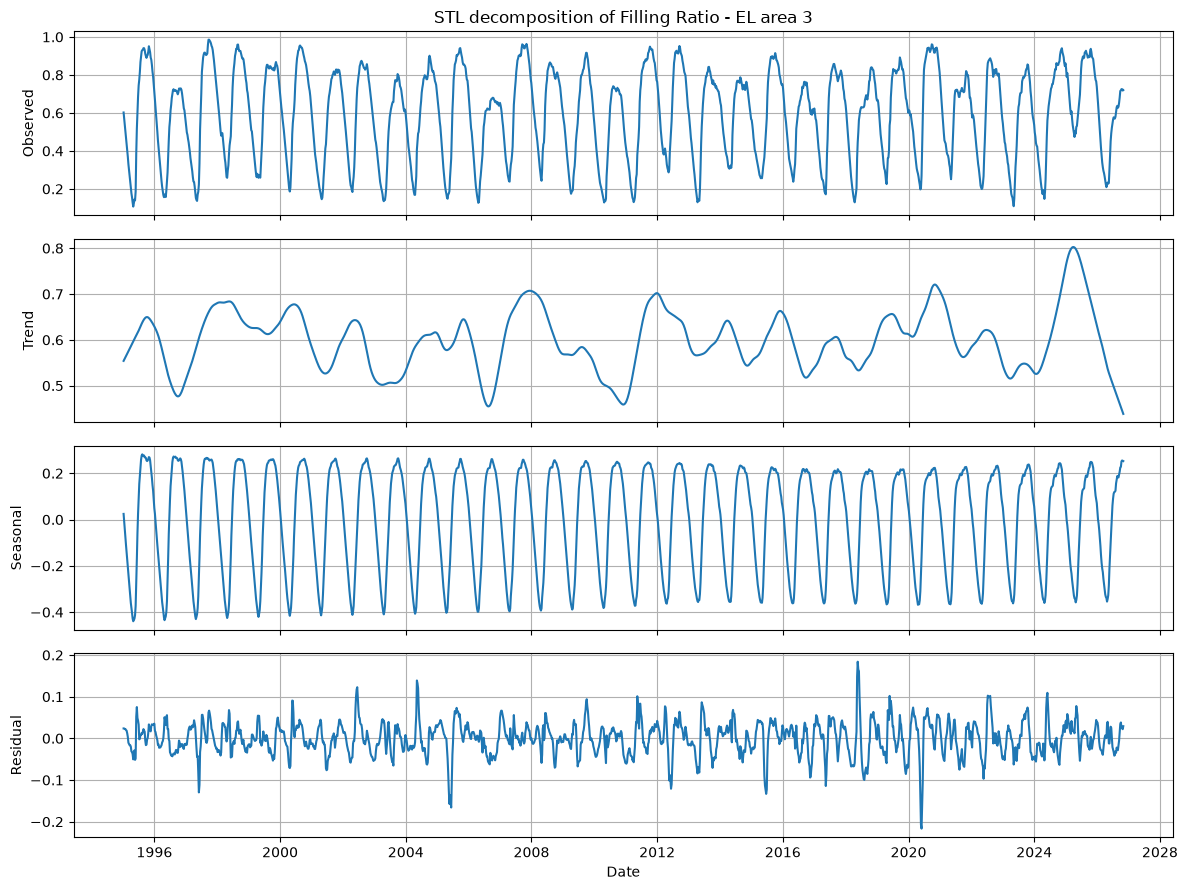

In [23]:
# Test the default selection and returned plot.
fig = plot_stl_decomposition(df_mag)
assert isinstance(fig, plt.Figure)
assert len(fig.axes) == 4
plt.show()


### 4.4 Spectrogram

In [24]:
import numpy as np
from scipy.signal import spectrogram

# Defining spectrogram function with parameters as requested.
def plot_spectrogram(
    df_mag,
    area_type="EL",
    area_number=3,
    window_length=52,
    window_overlap=26,):

    # Selecting data by area type and number function parameters.
    data = df_mag.loc[
        (df_mag["Area Type"] == area_type)
        & (df_mag["Area Number"] == area_number),
        ["Date", "Filling Ratio"],
    ].dropna(subset=["Date", "Filling Ratio"]).copy()

    # Creating pd datetime objects for plotting.
    data["Date"] = pd.to_datetime(data["Date"])
    data = data.sort_values("Date")

    # Defining errors to be raised in potentially common cases.
    if data.empty:
        raise ValueError(f"No data found for {area_type} area {area_number}.")
    if window_length < 2 or not 0 <= window_overlap < window_length:
        raise ValueError("window_length must be at least 2 and window_overlap must be smaller.")
    if len(data) < window_length:
        raise ValueError("There are fewer observations than the window length.")

    # Creating spectrogram using spectrogram() function.
    frequencies, times, power = spectrogram(
        data["Filling Ratio"].to_numpy(),
        fs=52,
        nperseg=window_length,
        noverlap=window_overlap,)

    # Converting power to decibels for easier plotting.
    power_db = 10 * np.log10(np.maximum(power, np.finfo(float).tiny))

    # Plotting.
    fig, ax = plt.subplots(figsize=(12, 5))
    mesh = ax.pcolormesh(times, frequencies, power_db, shading="auto")
    fig.colorbar(mesh, ax=ax, label="Power (dB)")
    ax.set_title(f"Spectrogram of Filling Ratio - {area_type} area {area_number}")
    ax.set_xlabel("Time (years from start)")
    ax.set_ylabel("Frequency (cycles per year)")
    fig.tight_layout()
    return fig


### 4.5 Spectrogram Function Test

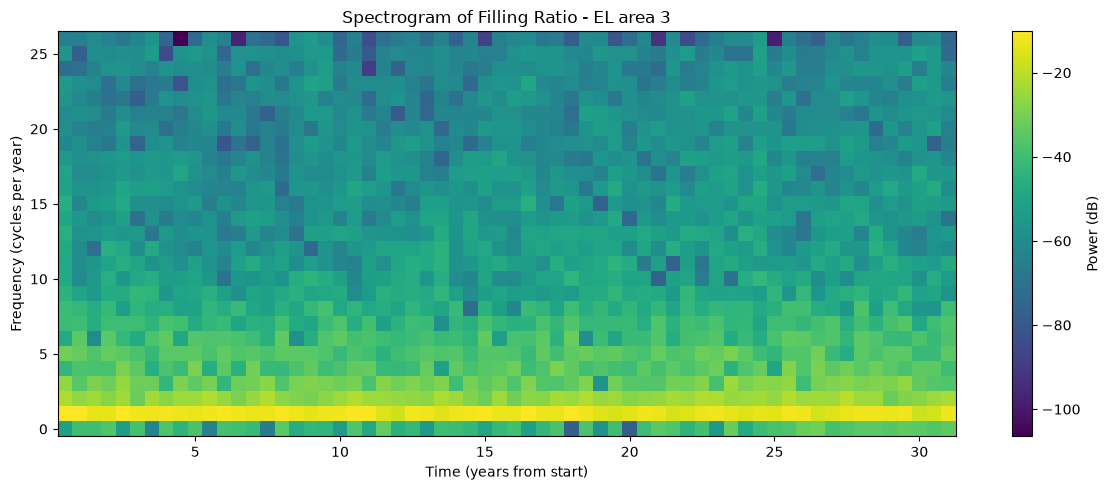

In [25]:
fig = plot_spectrogram(df_mag)
assert isinstance(fig, plt.Figure)
assert len(fig.axes) == 2  # Plot and colorbar
plt.show()
